**Pharmacy Sales & Drug Analysis**

In this notebook we will analyze pharmacy sales data to find medicine usage trends and revenue patterns. We will look at top-selling medicines, monthly sales growth, and compare branded vs generic medicines.

**Import Libraries**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

**Load the dataset**

In [2]:
df = pd.read_csv('/content/pharmacy_sales.csv')
df.head()

,Date,Medicine_Name,Drug_Type,Category,Quantity_Sold,Unit_Price,Total_Revenue
0,2023-01-01,Ibuprofen 400mg,Generic,Pain Relief,33,2.85,94.05
1,2023-01-01,Ibuprofen 400mg,Generic,Pain Relief,36,2.88,103.68
2,2023-01-01,Omeprazole 20mg,Generic,Gastric,28,3.28,91.84
3,2023-01-01,Calpol 500mg,Branded,Pain Relief,39,5.39,210.21
4,2023-01-01,Norvasc 5mg,Branded,Blood Pressure,37,10.60,392.20


**Check the shape of the dataset**

In [3]:
df.shape

(6000, 7)

**See all column names and their data types**

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           6000 non-null   object 
 1   Medicine_Name  6000 non-null   object 
 2   Drug_Type      6000 non-null   object 
 3   Category       6000 non-null   object 
 4   Quantity_Sold  6000 non-null   int64  
 5   Unit_Price     6000 non-null   float64
 6   Total_Revenue  6000 non-null   float64
dtypes: float64(2), int64(1), object(4)
memory usage: 328.3+ KB


In [5]:
df.describe()

,Quantity_Sold,Unit_Price,Total_Revenue
count,6000.000000,6000.000000,6000.000000
mean,20.548667,7.721537,157.993630
std,11.547692,4.706629,140.736645
min,1.000000,1.380000,1.390000
25%,10.000000,3.777500,52.940000
50%,21.000000,6.470000,114.490000
75%,31.000000,10.692500,217.300000
max,40.000000,19.440000,760.000000


**Check for missing values and duplicates**

In [6]:
print("Missing values:")
print(df.isnull().sum())
print()
print("Duplicates:", df.duplicated().sum())

Missing values:
Date             0
Medicine_Name    0
Drug_Type        0
Category         0
Quantity_Sold    0
Unit_Price       0
Total_Revenue    0
dtype: int64

Duplicates: 0


**Convert Date column to proper date format**

In [7]:
df['Date'] = pd.to_datetime(df['Date'])
print("Date converted!")
print("Date range:", df['Date'].min(), "to", df['Date'].max())

Date converted!
Date range: 2023-01-01 00:00:00 to 2024-12-31 00:00:00


---
## **1. Top Selling Medicines**

**Top 10 medicines by total quantity sold**

In [8]:
# group by medicine name and add up the quantity sold
top_medicines = df.groupby('Medicine_Name')['Quantity_Sold'].sum().sort_values(ascending=False)
top_medicines

,Quantity_Sold
Medicine_Name,
Amoxicillin 250mg,6861
Advil 400mg,6602
Salbutamol Inhaler,6484
Cetirizine 10mg,6455
Augmentin 625mg,6321
Lipitor 10mg,6298
Norvasc 5mg,6201
Amlodipine 5mg,6168
Atorvastatin 10mg,6160


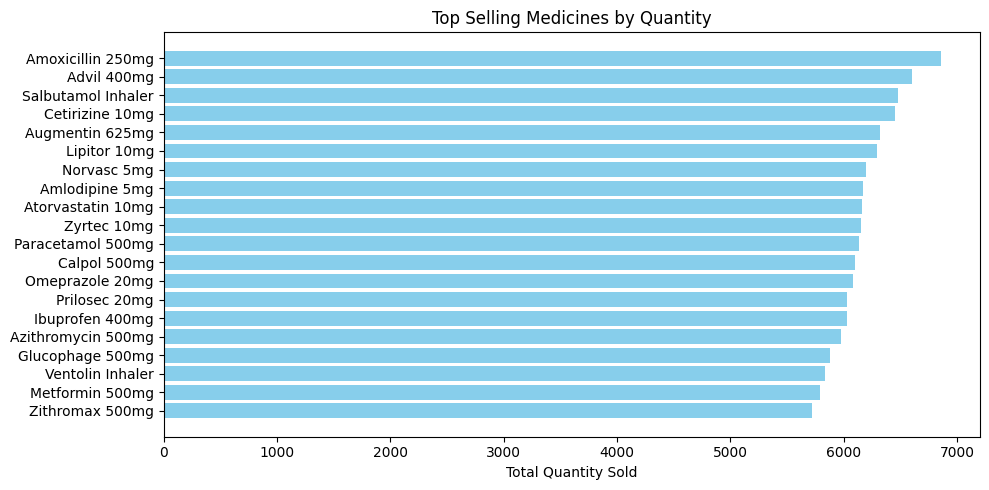

In [9]:
plt.figure(figsize=(10, 5))
plt.barh(top_medicines.index[::-1], top_medicines.values[::-1], color='skyblue')
plt.xlabel('Total Quantity Sold')
plt.title('Top Selling Medicines by Quantity')
plt.tight_layout()
plt.show()

**Top 10 medicines by total revenue**

In [10]:
# group by medicine name and add up the revenue
top_revenue = df.groupby('Medicine_Name')['Total_Revenue'].sum().sort_values(ascending=False)
top_revenue

,Total_Revenue
Medicine_Name,
Zithromax 500mg,102738.95
Augmentin 625mg,97172.22
Lipitor 10mg,88402.74
Ventolin Inhaler,87551.59
Glucophage 500mg,70646.54
Norvasc 5mg,62017.13
Prilosec 20mg,54396.27
Advil 400mg,49512.25
Azithromycin 500mg,47974.22


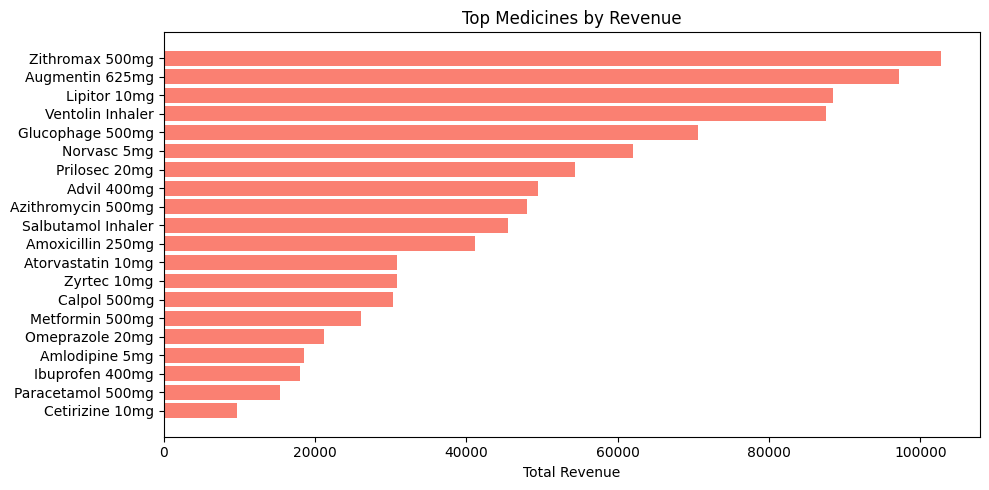

In [11]:
plt.figure(figsize=(10, 5))
plt.barh(top_revenue.index[::-1], top_revenue.values[::-1], color='salmon')
plt.xlabel('Total Revenue')
plt.title('Top Medicines by Revenue')
plt.tight_layout()
plt.show()

---
## **2. Monthly Sales Growth**

**Create Month-Year column for grouping**

In [12]:
# extract month and year from the date
df['Month'] = df['Date'].dt.month
df['Year'] = df['Date'].dt.year
df['Month_Year'] = df['Date'].dt.to_period('M')

df.head()

,Date,Medicine_Name,Drug_Type,Category,Quantity_Sold,Unit_Price,Total_Revenue,Month,Year,Month_Year
0,2023-01-01,Ibuprofen 400mg,Generic,Pain Relief,33,2.85,94.05,1,2023,2023-01
1,2023-01-01,Ibuprofen 400mg,Generic,Pain Relief,36,2.88,103.68,1,2023,2023-01
2,2023-01-01,Omeprazole 20mg,Generic,Gastric,28,3.28,91.84,1,2023,2023-01
3,2023-01-01,Calpol 500mg,Branded,Pain Relief,39,5.39,210.21,1,2023,2023-01
4,2023-01-01,Norvasc 5mg,Branded,Blood Pressure,37,10.60,392.20,1,2023,2023-01


**Monthly total revenue**

In [13]:
# calculate total revenue for each month
monthly_revenue = df.groupby('Month_Year')['Total_Revenue'].sum()
monthly_revenue

,Total_Revenue
Month_Year,
2023-01,41301.15
2023-02,35026.34
2023-03,38562.80
2023-04,44901.85
2023-05,40566.42
2023-06,35772.11
2023-07,39123.14
2023-08,41864.15
2023-09,41552.56


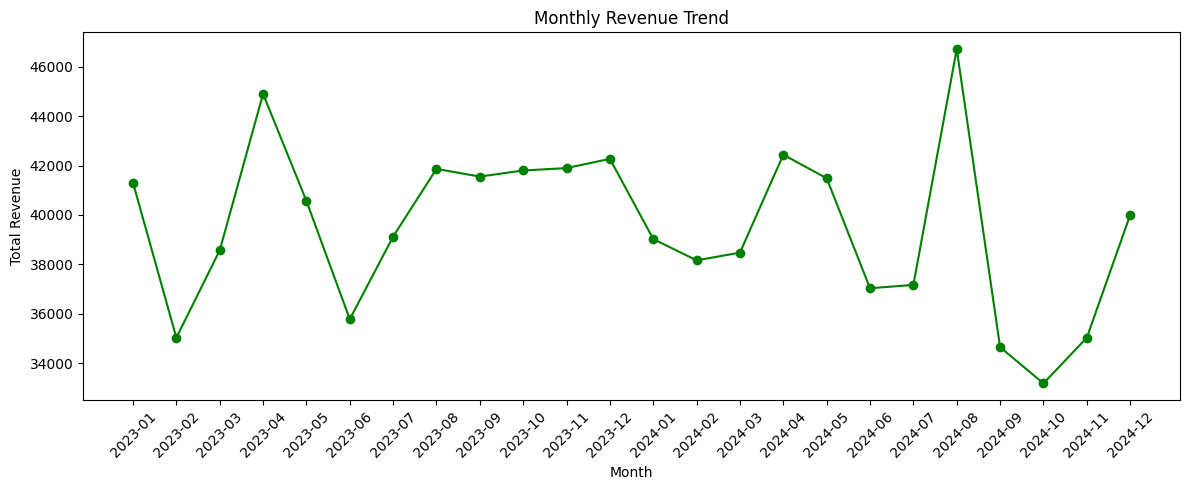

In [14]:
plt.figure(figsize=(12, 5))
plt.plot(monthly_revenue.index.astype(str), monthly_revenue.values, marker='o', color='green')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.title('Monthly Revenue Trend')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Monthly total quantity sold**

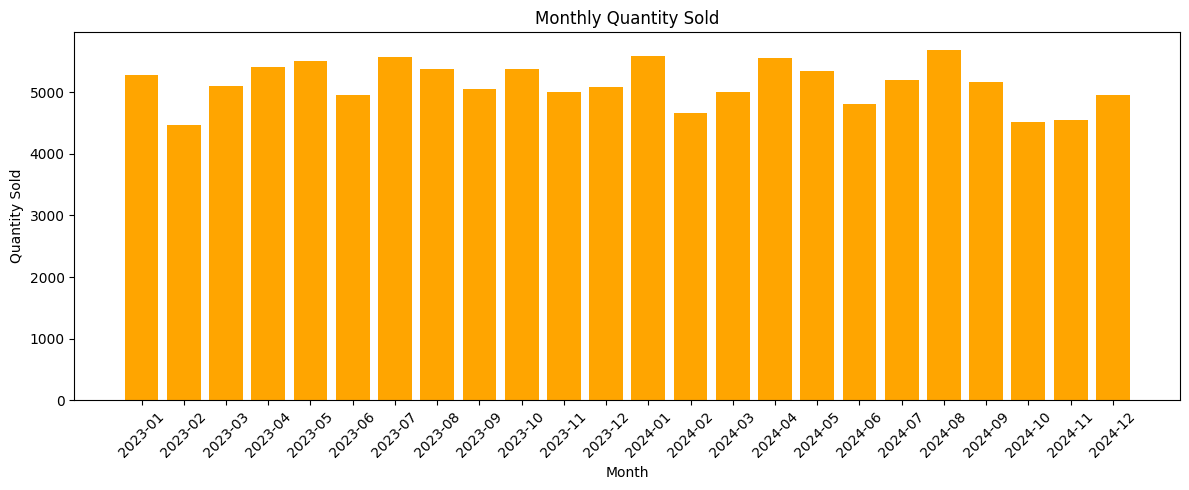

In [15]:
# calculate total quantity sold for each month
monthly_quantity = df.groupby('Month_Year')['Quantity_Sold'].sum()

plt.figure(figsize=(12, 5))
plt.bar(monthly_quantity.index.astype(str), monthly_quantity.values, color='orange')
plt.xlabel('Month')
plt.ylabel('Quantity Sold')
plt.title('Monthly Quantity Sold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Monthly sales growth percentage**

In [16]:
# calculate the percentage change from one month to next
monthly_growth = monthly_revenue.pct_change() * 100
monthly_growth = monthly_growth.round(2)
monthly_growth

,Total_Revenue
Month_Year,
2023-01,NaN
2023-02,-15.19
2023-03,10.10
2023-04,16.44
2023-05,-9.66
2023-06,-11.82
2023-07,9.37
2023-08,7.01
2023-09,-0.74


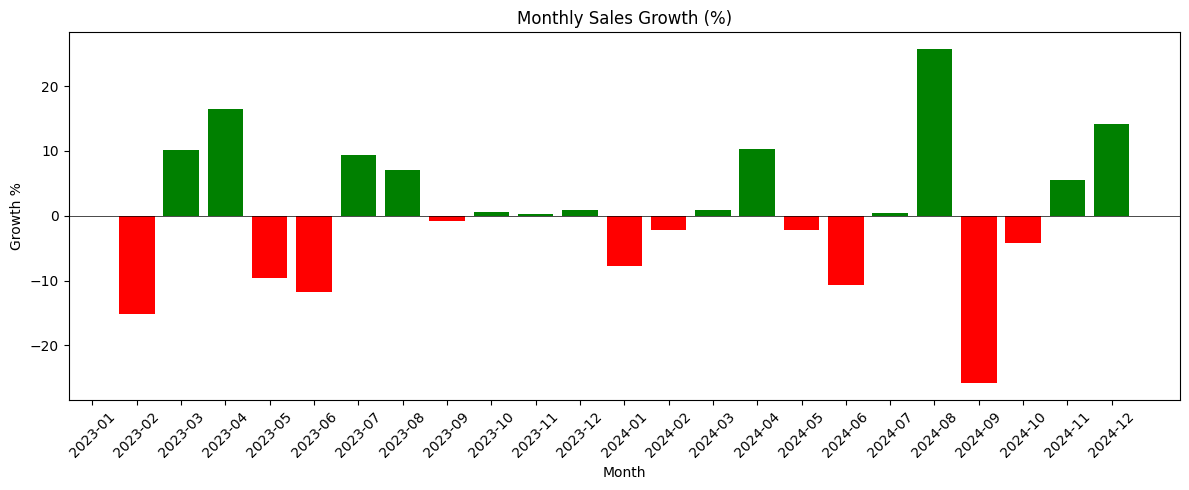

In [17]:
plt.figure(figsize=(12, 5))
colors = ['green' if x >= 0 else 'red' for x in monthly_growth.values]
plt.bar(monthly_growth.index.astype(str), monthly_growth.values, color=colors)
plt.xlabel('Month')
plt.ylabel('Growth %')
plt.title('Monthly Sales Growth (%)')
plt.xticks(rotation=45)
plt.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
plt.tight_layout()
plt.show()

---
## **3. Branded vs Generic Medicines**

**Count of branded vs generic sales**

In [18]:
drug_type_counts = df['Drug_Type'].value_counts()
drug_type_counts

,count
Drug_Type,
Generic,3016
Branded,2984


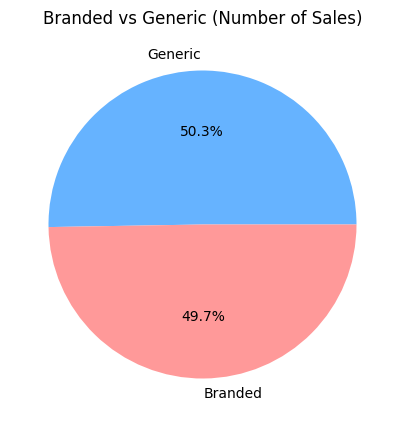

In [19]:
plt.figure(figsize=(5, 5))
plt.pie(drug_type_counts.values, labels=drug_type_counts.index, autopct='%1.1f%%', colors=['#66b3ff', '#ff9999'])
plt.title('Branded vs Generic (Number of Sales)')
plt.show()

**Total revenue - Branded vs Generic**

In [20]:
# total revenue for each drug type
revenue_by_type = df.groupby('Drug_Type')['Total_Revenue'].sum()
revenue_by_type

,Total_Revenue
Drug_Type,
Branded,673591.73
Generic,274370.05


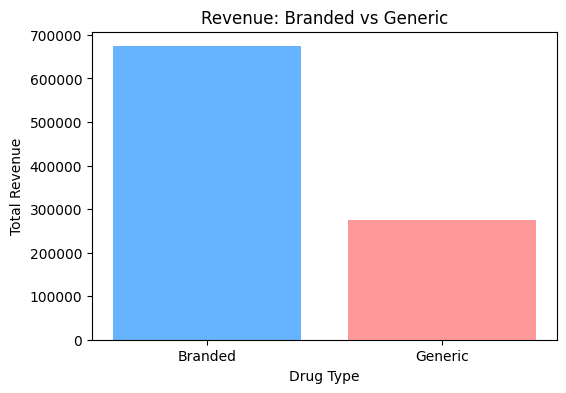

In [21]:
plt.figure(figsize=(6, 4))
plt.bar(revenue_by_type.index, revenue_by_type.values, color=['#66b3ff', '#ff9999'])
plt.xlabel('Drug Type')
plt.ylabel('Total Revenue')
plt.title('Revenue: Branded vs Generic')
plt.show()

**Total quantity sold - Branded vs Generic**

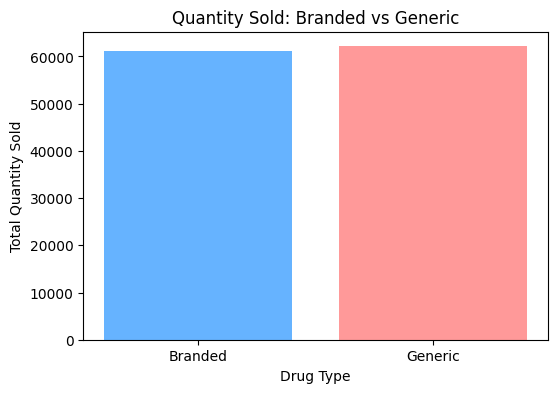

In [22]:
quantity_by_type = df.groupby('Drug_Type')['Quantity_Sold'].sum()

plt.figure(figsize=(6, 4))
plt.bar(quantity_by_type.index, quantity_by_type.values, color=['#66b3ff', '#ff9999'])
plt.xlabel('Drug Type')
plt.ylabel('Total Quantity Sold')
plt.title('Quantity Sold: Branded vs Generic')
plt.show()

**Average unit price - Branded vs Generic**

In [23]:
avg_price_by_type = df.groupby('Drug_Type')['Unit_Price'].mean().round(2)
print("Average price:")
print(avg_price_by_type)

Average price:
Drug_Type
Branded    11.07
Generic     4.41
Name: Unit_Price, dtype: float64


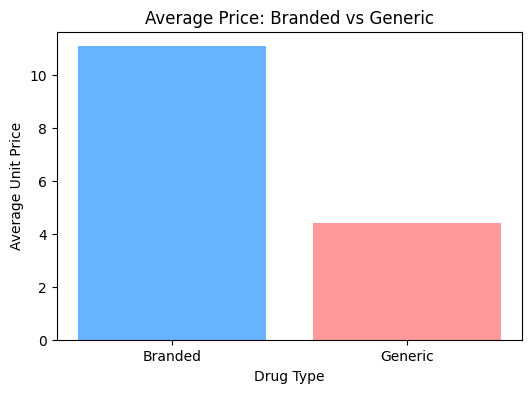

In [24]:
plt.figure(figsize=(6, 4))
plt.bar(avg_price_by_type.index, avg_price_by_type.values, color=['#66b3ff', '#ff9999'])
plt.xlabel('Drug Type')
plt.ylabel('Average Unit Price')
plt.title('Average Price: Branded vs Generic')
plt.show()

---
## **4. Medicine Usage Trends**

**Sales by medicine category**

In [25]:
# see which category of medicine sells the most
category_sales = df.groupby('Category')['Quantity_Sold'].sum().sort_values(ascending=False)
category_sales

,Quantity_Sold
Category,
Antibiotic,24881
Pain Relief,24867
Allergy,12607
Cholesterol,12458
Blood Pressure,12369
Respiratory,12322
Gastric,12115
Diabetes,11673


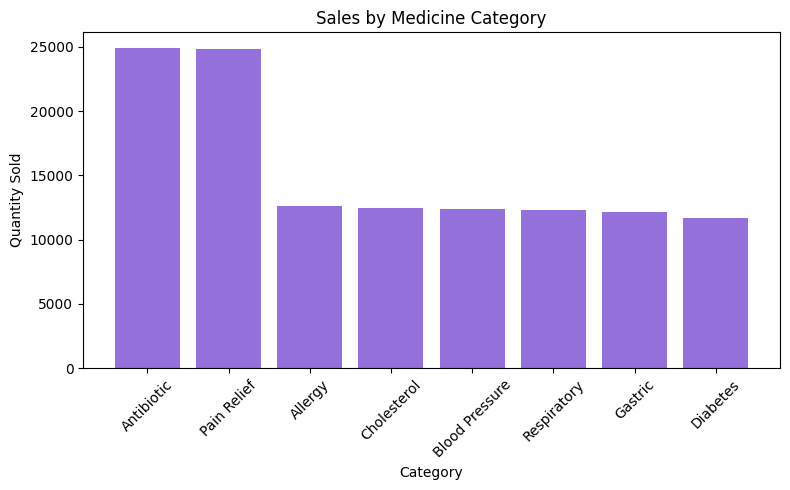

In [26]:
plt.figure(figsize=(8, 5))
plt.bar(category_sales.index, category_sales.values, color='mediumpurple')
plt.xlabel('Category')
plt.ylabel('Quantity Sold')
plt.title('Sales by Medicine Category')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Revenue by medicine category**

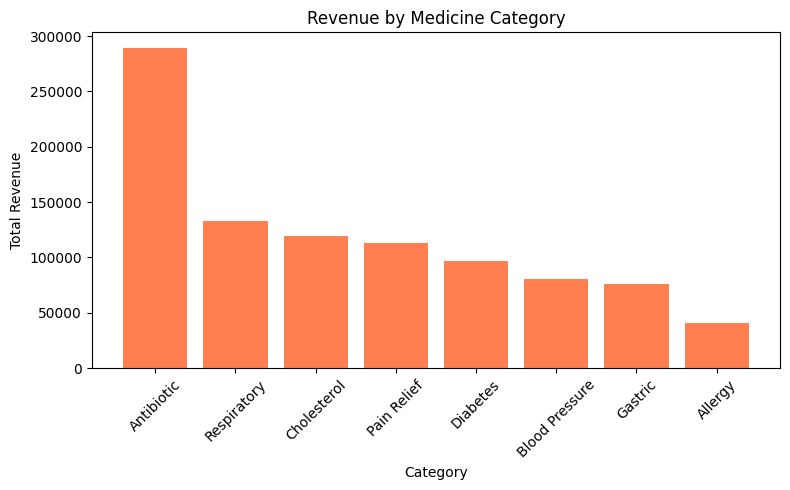

In [27]:
category_revenue = df.groupby('Category')['Total_Revenue'].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(category_revenue.index, category_revenue.values, color='coral')
plt.xlabel('Category')
plt.ylabel('Total Revenue')
plt.title('Revenue by Medicine Category')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Yearly comparison**

In [28]:
# compare revenue between 2023 and 2024
yearly_revenue = df.groupby('Year')['Total_Revenue'].sum()
print("Revenue by year:")
print(yearly_revenue)

Revenue by year:
Year
2023    484637.62
2024    463324.16
Name: Total_Revenue, dtype: float64


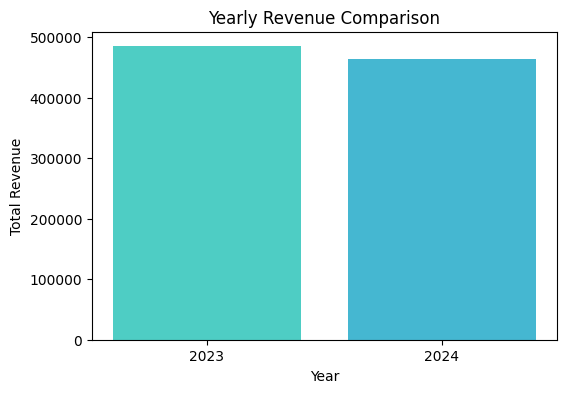

In [29]:
plt.figure(figsize=(6, 4))
plt.bar(yearly_revenue.index.astype(str), yearly_revenue.values, color=['#4ecdc4', '#45b7d1'])
plt.xlabel('Year')
plt.ylabel('Total Revenue')
plt.title('Yearly Revenue Comparison')
plt.show()

---
## **Summary**

In [30]:
print("SUMMARY")
print()
print("Total sales records:", len(df))
print("Total revenue:", round(df['Total_Revenue'].sum(), 2))
print("Total quantity sold:", df['Quantity_Sold'].sum())
print()
print("Top selling medicine (by quantity):", top_medicines.index[0])
print("Top revenue medicine:", top_revenue.index[0])
print()
print("Branded revenue:", round(revenue_by_type['Branded'], 2))
print("Generic revenue:", round(revenue_by_type['Generic'], 2))
print()
print("Average branded price:", avg_price_by_type['Branded'])
print("Average generic price:", avg_price_by_type['Generic'])

SUMMARY

Total sales records: 6000
Total revenue: 947961.78
Total quantity sold: 123292

Top selling medicine (by quantity): Amoxicillin 250mg
Top revenue medicine: Zithromax 500mg

Branded revenue: 673591.73
Generic revenue: 274370.05

Average branded price: 11.07
Average generic price: 4.41
